# Работа с текстовыми данными

**Цель:** Обучить модель машинного обучения для классификации коротких текстов используя
подход на основе токенизации.

Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

Скрипт подготовлен по материалам: [Проворовой (Радыгиной) Анны Александровны](https://www.hse.ru/staff/provorovaaa/)

## Обработка естественного языка или **NLP (Natural Language Processing)**

NLP занимается применением алгоритмов Machine Learning для текстовых данных.

*Основные определения:*

Сначала текст разбивается на **текстовые единицы (токены)**, например, символы, слова, словосочетания, предложения, абзацы и т.д. Чаще всего разбивают на слова.

Токены образуют **словарь**, который может быть отсортирован по алфавиту.
Также в NLP применяются термины «документ» и «корпус».

**Документ** — это совокупность токенов, которые принадлежат одной смысловой единице. В качестве документа может выступать предложение, комментарий или пост пользователя.

**Корпус** — это генеральная совокупность всех документов.

**Лемматизация** — это процесс приведения словоформы к её нормальной (словарной) форме, известной как лемма. Этот метод используется в морфологическом анализе языка и позволяет свести различные формы одного и того же слова к единому значению. Например, слова "бегу", "бежал" и "бегущий" будут приведены к лемме "бежать".

**Стемминг** — это процесс, используемый в обработке естественного языка (NLP) для уменьшения словоформ до их основы или корня, известного как стем. Этот метод позволяет свести различные формы одного и того же слова к единой форме, что упрощает анализ текста и поиск информации.

Как вы уже знаете, алгоритмы машинного обучения работают с числами. Соответственно, нам нужно придумать, как представить наш текст с помощью чисел.

### Bag-of-words

Bag of Words или мешок слов — это модель, часто используемая при обработке текстов, представляющая собой неупорядоченный набор слов, входящих в обрабатываемый текст. Это одна из самых простых методик векторизации текста. В логике BOW два предложения могут называться одинаковыми, если содержат один и тот же набор слов.

BOW широко используется для решения следующих задач:

1. Обработка естественного языка
2. Получение информации из документов
3. Классификация документов.


Глобально работа этого алгоритма состоит из следующих шагов:

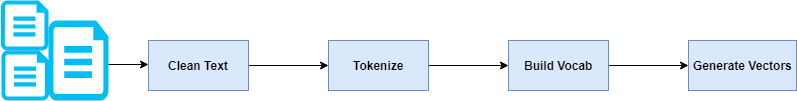

[Источник](https://www.freecodecamp.org/news/an-introduction-to-bag-of-words-and-how-to-code-it-in-python-for-nlp-282e87a9da04/)

Сгенерированные векторы можно использовать в качестве входных данных для машинного обучения.

Рассмотрим пример. Возьмём два предложения:

1. *"John likes to watch movies. Mary likes movies too."*
2. *"John also likes to watch football games."*

Эти два предложения также могут быть представлены набором слов.

1. *['John', 'likes', 'to', 'watch', 'movies.', 'Mary', 'likes', 'movies', 'too.']*
2. *['John', 'also', 'likes', 'to', 'watch', 'football', 'games']*

Преобразуем эти наборы в частотные словари:

1. *{"John":1,"likes":2,"to":1,"watch":1,"movies":2,"Mary":1,"too":1}*
2. *{"John":1,"also":1,"likes":1,"to":1,"watch":1,"football":1,   "games":1}*




Пусть эти предложения являются частью большого документа. Тогда общий частотный словарь будет выглядеть так:

{"John":2,
"likes":3,
"to":2,
"watch":2,
"movies":2,
"Mary":1,
"too":1,  
"also":1,
"football":1,
"games":1}

Этот словарь всех слов в документе и будет использоваться для создания векторов для каждого предложения.

**Важно**: длина вектора всегда равна длине словаря! В данном случае, длина вектора равна 10.

Таким образом, векторы наших предложений будут выглядеть так:

1. *John likes to watch movies. Mary likes movies too.* => [1, 2, 1, 1, 2, 1, 1, 0, 0, 0]
2. *John also likes to watch football games.* => [1, 1, 1, 1, 0, 0, 0, 1, 1, 1]

**Важно**: в предложении 1 слово "likes" стоит на второй позиции и встречается два раза. Таким образом, второй элемент нашего вектора для предложения 1 будет равен 2.

Большой документ, в котором сгенерированный словарь огромен, может привести к созданию вектора с множеством нулевых значений. Это называется разреженным вектором. Разреженные векторы требуют больше памяти и вычислительных ресурсов при моделировании. Огромное количество позиций или размеров может сделать процесс моделирования очень сложным для традиционных алгоритмов.


##Этапы алгоритма



### Шаг 1. Подготовка текста.

Начнем с приведения к нижнему регистру, удалени всех "лишних символов" и удаления стоп-слов.

**Стоп-слова** — это слова, которые не содержат достаточного значения для использования без нашего алгоритма. Нам бы не хотелось, чтобы эти слова занимали место в нашей базе данных или отнимали ценное время обработки. Для этого мы можем легко удалить их, сохранив список слов, которые вы считаете стоп-словами. В нашем случае, мы будем использовать библиотеку nltk.  В ней уже есть набор предопределенных стоп-слов для каждого языка.

### Шаг 2. Примение токенизации и лемматизации (стемминга) ко всем предложениям

**Токенизация** — это процесс разбиения последовательности строк на части, такие как слова, ключевые слова, фразы, символы и другие элементы, называемые токенами. Токенами могут быть отдельные слова, фразы или даже целые предложения. В процессе токенизации некоторые символы, например, знаки препинания, отбрасываются.

Сразу после токенизации можно выполнить лемматизацию - приведение слов к их нормальной форме.

*Почему это полезно сделать при применении Bag-of-Words?*

### Шаг 3. Создайте словарный запас и создайте векторы

Из всех слов в документе создаётся словарный запас, на основании которого строятся векторы для всех текстов.

####Понимание Bag-of-words:

Модель BoW учитывает только то, встречается ли известное слово в документе или нет. Его не волнуют смысл, контекст и порядок, в котором они появляются.
Это дает представление о том, что аналогичные документы будут иметь одинаковое количество слов. Другими словами, чем более похожи слова в двух документах, тем более похожими могут быть документы.

Ограничения BoW:

1. Контекст: Базовый подход BOW не учитывает значение слова в документе (контексте).

2. Размер вектора: Для большого документа размер вектора может быть огромным, что потребует большого количества вычислений и времени.

## Необходимые библиотеки

In [ ]:
# установим библиотеку, содержащую стоп-слова
%pip install nltk

In [ ]:
# надёжный инструмент для лемматизации русского языка от Яндекса
%pip install pymystem3

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import HashingVectorizer
from nltk.stem.snowball import SnowballStemmer

import re
from pymystem3 import Mystem
from nltk.corpus import stopwords
import nltk

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns

import gdown

## Загружаем данные

In [ ]:
import pandas as pd

# Возьмем данные об отзывах на женскую одежду
url = "https://raw.githubusercontent.com/sismetanin/rureviews/master/women-clothing-accessories.3-class.balanced.csv"

# Указываем разделитель табуляцию (\t) и пропускаем потенциально битые строки
df = pd.read_csv(url, sep='\t', on_bad_lines='skip')

# Задаем понятные названия колонкам (текст отзыва и метка тональности)
df.columns = ['text', 'sentiment']

# Проверяем, что всё загрузилось успешно
display(df.head())
print(df['sentiment'].value_counts())

,text,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64


In [ ]:
# Исправляем опечатку в колонке sentiment ('neautral' -> 'neutral')
df['sentiment'] = df['sentiment'].str.replace('neautral', 'neutral', regex=False)

# Создаем уникальный идентификатор для каждой строки
df.insert(0, 'id', range(0, len(df)))

# Проверяем уникальность классов и смотрим на первые строки с новым id
print(df['sentiment'].value_counts())
display(df.head())

sentiment
negative    30000
neutral     30000
positive    30000
Name: count, dtype: int64


,id,text,sentiment
0,0,качество плохое пошив ужасный (горловина напер...,negative
1,1,"Товар отдали другому человеку, я не получила п...",negative
2,2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,3,"товар не пришел, продавец продлил защиту без м...",negative
4,4,"Кофточка голая синтетика, носить не возможно.",negative


Описание датасета:

| Название колонки        | Описание |
|------------------------|----------|
| **id**         | Индентификатор отзыва. |
| **text**         | Текст отзыва на женскую одежду. |
| **sentiment**| Сентимент или настроение текста (negative - негативный, neutral - нейтральный, positive - позитивный). |

In [ ]:
# Информация о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         90000 non-null  int64 
 1   text       90000 non-null  object
 2   sentiment  90000 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.1+ MB


In [ ]:
# Количество строк и колонок
df.shape

(90000, 3)

## Подготовка данных к последующему анализу

In [ ]:
# Количество дубликатов по тексту отзыва и сентименту
df.duplicated(['text', 'sentiment']).sum()

np.int64(2250)

In [ ]:
# Удаляем дубликаты по тексту и классу, оставляя первый вариант
df = df.drop_duplicates(subset=['text', 'sentiment']).reset_index(drop=True)

# Проверяем, сколько строк осталось
df.shape

(87750, 3)

In [ ]:
# Кодируем строковые метки в числа (0, 1, 2)
sentiment_mapping = {'negative': 0, 'neutral': 1, 'positive': 2}
df['sentiment_encoded'] = df['sentiment'].map(sentiment_mapping)

In [ ]:
# Отбор 5000 отзывов с сохранением баланса классов
sample_size_per_class = 5000 // 3
df_sample = (
    df.groupby('sentiment_encoded', group_keys=False)
    .apply(lambda x: x.sample(n=sample_size_per_class, random_state=42))
    .reset_index(drop=True)
)

print("Размер выборки и распределение классов:")
print(df_sample['sentiment'].value_counts())

Размер выборки и распределение классов:
sentiment
negative    1666
neutral     1666
positive    1666
Name: count, dtype: int64


/tmp/ipykernel_605/1449500426.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=sample_size_per_class, random_state=42))


### Предобработка текста


In [ ]:
# Подготовка инструментов для стемминга и лемматизации
nltk.download('stopwords')
stop_words = set(stopwords.words('russian')) # готовый словарь русских стоп-слов
additional_stops = ['это', 'весь', 'который', 'свой', 'также'] # можно также добавить свои слова, например, которые отражают какую-то специфику предметной области
stop_words.update(additional_stops)

stemmer = SnowballStemmer("russian")
mystem = Mystem()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
Installing mystem to /root/.local/bin/mystem from http://download.cdn.yandex.net/mystem/mystem-3.1-linux-64bit.tar.gz


In [ ]:
# Функция предобработки со стеммингом
def preprocess_stemming(text):
    text = str(text).lower() # приводим к нижнему регистру
    text = text.replace('ё', 'е')  # Заменяем ё на е, чтобы не терять информацию
    text = re.sub(r'[^а-яa-z\s]', ' ', text) # убираем знаки препинания, специальные символы, числа
    tokens = text.split() # токенизируем (разбиваем текст на отдельные слова)
    stemmed_tokens = [
        stemmer.stem(token) # проводим стемминг
        for token in tokens
        if token not in stop_words # удаляем слова, которые находятся в списке стоп-слов
    ]
    return ' '.join(stemmed_tokens)

In [ ]:
# Функция предобработки с лемматизацией
def preprocess_lemmatization(text):
    text = str(text).lower() # приводим к нижнему регистру
    text = text.replace('ё', 'е')  # Заменяем ё на е, чтобы не терять информацию
    text = re.sub(r'[^а-яa-z\s]', ' ', text) # убираем знаки препинания, специальные символы, числа
    lemmas = mystem.lemmatize(text) # проводим лемматизацию (приведение слов к инфинитиву)
    lemmatized_tokens = [
        token.strip()
        for token in lemmas
        if token.strip() not in stop_words # удаляем слова, которые находятся в списке стоп-слов
    ]
    return ' '.join(lemmatized_tokens)

In [ ]:
# Применяем функции предобработки со стеммингом и с лемматизацией
df_sample['clean_stem'] = df_sample['text'].apply(preprocess_stemming)
df_sample['clean_lemma'] = df_sample['text'].apply(preprocess_lemmatization)

####Пример полученной обработки

In [ ]:
df_sample

,id,text,sentiment,sentiment_encoded,clean_stem,clean_lemma
0,21711,получила совсем не то что фото! модель не соот...,negative,0,получ фот модел соответств фот оплачива быстр ...,получать фото модель соответствовать ...
1,27901,"Прислал брак. При открытии спора, я готова бы...",negative,0,присла брак открыт спор готов отмен спор случа...,присылать брак открытие спор готовый о...
2,22782,"Вместо заказанного товара, я получила какую-то...",negative,0,вмест заказа товар получ как кисточк откр спор...,вместо заказывать товар получать кисточ...
3,7841,Материал не особо качественный.\r\nНа рост выш...,negative,0,материа особ качествен рост выш совет брат дан...,материал особо качественный рост высоко ...
4,26008,"Товар шёл долго очень,открыла спор . Колготки ...",negative,0,товар шел долг очен откр спор колготк пришл кр...,товар идти долго очень открывать спор ко...
...,...,...,...,...,...,...
4993,64135,"клевая майка, качество трикотажа хорошее, шла ...",positive,2,клев майк качеств трикотаж хорош шла недолг ре...,клевый майка качество трикотаж хороший ид...
4994,86176,Товар пришёл за 2 недели. Размерная сетка соот...,positive,2,товар пришел недел размерн сетк соответств сти...,товар приходить неделя размерный сетка с...
4995,81701,"Была по размеру, после деликатной стирки, ссел...",positive,2,размер деликатн стирк ссел качеств средн вообщ...,размер деликатный стирка расседаться ка...
4996,62049,"Куртка пришла за 2 недели, за это спасибо! Что...",positive,2,куртк пришл недел спасиб каса сам куртк скор к...,куртка приходить неделя спасибо касать...


In [ ]:
# Векторизация и разбиение (с сохранением стратификации)
y = df_sample['sentiment_encoded']

# Делим выборку 80/20 с сохранением пропорций классов (stratify=y)
X_train_s, X_test_s, y_train, y_test = train_test_split(
    df_sample['clean_stem'], y, test_size=0.2, random_state=42, stratify=y
)
X_train_l = df_sample.loc[X_train_s.index, 'clean_lemma']
X_test_l = df_sample.loc[X_test_s.index, 'clean_lemma']

In [ ]:
# CountVectorizer (Мешок слов)
vec_stem = CountVectorizer(max_features=3000) # ограничиваем количество признаков, параметр можно поменять и посмотреть, что будет
X_train_stem_vec = vec_stem.fit_transform(X_train_s)
X_test_stem_vec = vec_stem.transform(X_test_s)

vec_lemma = CountVectorizer(max_features=3000)
X_train_lemma_vec = vec_lemma.fit_transform(X_train_l)
X_test_lemma_vec = vec_lemma.transform(X_test_l)

## Обучение моделей и расчет метрик качества

In [ ]:
from sklearn.model_selection import GridSearchCV

# Кросс-валидация и подбор гиперпараметров

# Задаем сетку параметров для поиска (пробуем разную силу регуляризации C)
param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}

# Для стемминга
base_model_stem = LogisticRegression(max_iter=500, random_state=42)
grid_stem = GridSearchCV(
    estimator=base_model_stem,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
)
grid_stem.fit(X_train_stem_vec, y_train)

print(f'Лучшие параметры для стемминга: {grid_stem.best_params_}')
model_stem = grid_stem.best_estimator_
y_pred_stem = model_stem.predict(X_test_stem_vec)


# Для лемматизации
base_model_lemma = LogisticRegression(max_iter=500, random_state=42)
grid_lemma = GridSearchCV(
    estimator=base_model_lemma,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
)
grid_lemma.fit(X_train_lemma_vec, y_train)

print(f'Лучшие параметры для лемматизации: {grid_lemma.best_params_}')
model_lemma = grid_lemma.best_estimator_
y_pred_lemma = model_lemma.predict(X_test_lemma_vec)

Лучшие параметры для стемминга: {'C': 0.1}
Лучшие параметры для лемматизации: {'C': 0.1}


In [ ]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import accuracy_score, classification_report, f1_score

# Качество моделей

# Считаем метрики
metrics_stem = precision_recall_fscore_support(y_test, y_pred_stem, average=None)
metrics_lemma = precision_recall_fscore_support(
    y_test, y_pred_lemma, average=None
)

# Создаем красивый DataFrame для сравнения
comparison_df = pd.DataFrame({
    'Класс / Метрика': [
        'Negative (Precision)',
        'Negative (Recall)',
        'Negative (F1)',
        'Neutral (Precision)',
        'Neutral (Recall)',
        'Neutral (F1)',
        'Positive (Precision)',
        'Positive (Recall)',
        'Positive (F1)',
        'Accuracy (Общая)',
        'Macro F1 (Среднее)',
    ],
    'Стемминг': [
        metrics_stem[0][0],
        metrics_stem[1][0],
        metrics_stem[2][0],  # Negative
        metrics_stem[0][1],
        metrics_stem[1][1],
        metrics_stem[2][1],  # Neutral
        metrics_stem[0][2],
        metrics_stem[1][2],
        metrics_stem[2][2],  # Positive
        accuracy_score(y_test, y_pred_stem),
        f1_score(y_test, y_pred_stem, average='macro'),
    ],
    'Лемматизация': [
        metrics_lemma[0][0],
        metrics_lemma[1][0],
        metrics_lemma[2][0],  # Negative
        metrics_lemma[0][1],
        metrics_lemma[1][1],
        metrics_lemma[2][1],  # Neutral
        metrics_lemma[0][2],
        metrics_lemma[1][2],
        metrics_lemma[2][2],  # Positive
        accuracy_score(y_test, y_pred_lemma),
        f1_score(y_test, y_pred_lemma, average='macro'),
    ],
})

# Округляем значения для красоты
comparison_df['Стемминг'] = comparison_df[
    'Стемминг'
].round(3)
comparison_df['Лемматизация'] = comparison_df[
    'Лемматизация'
].round(3)

# Выводим таблицу
display(comparison_df)

,Класс / Метрика,Стемминг,Лемматизация
0,Negative (Precision),0.700,0.715
1,Negative (Recall),0.688,0.694
2,Negative (F1),0.694,0.704
3,Neutral (Precision),0.577,0.588
4,Neutral (Recall),0.607,0.631
5,Neutral (F1),0.592,0.609
6,Positive (Precision),0.836,0.850
7,Positive (Recall),0.808,0.814
8,Positive (F1),0.822,0.832
9,Accuracy (Общая),0.701,0.713


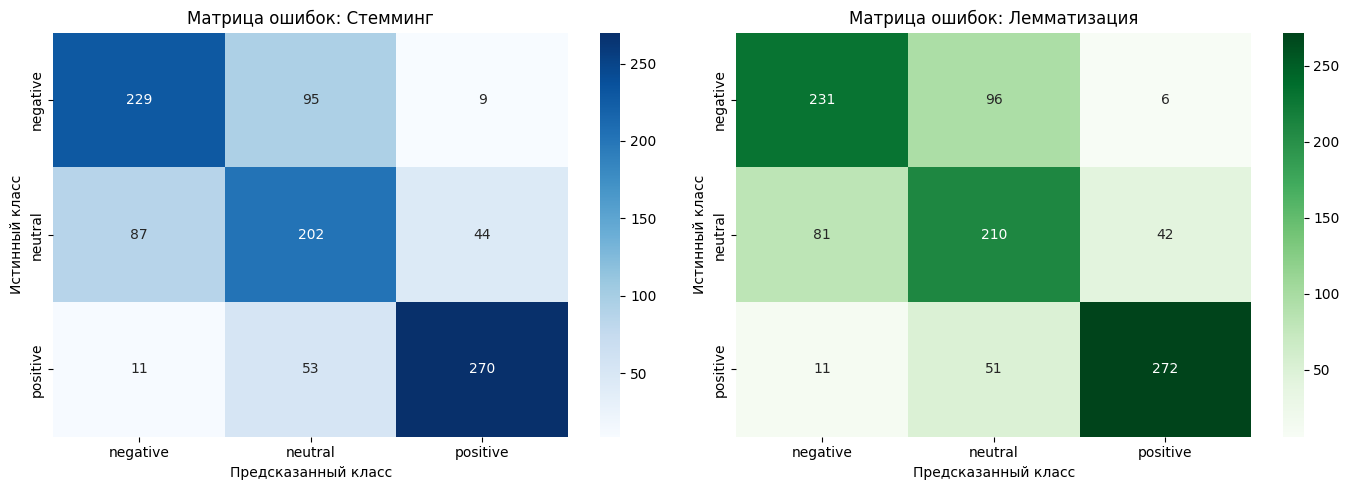

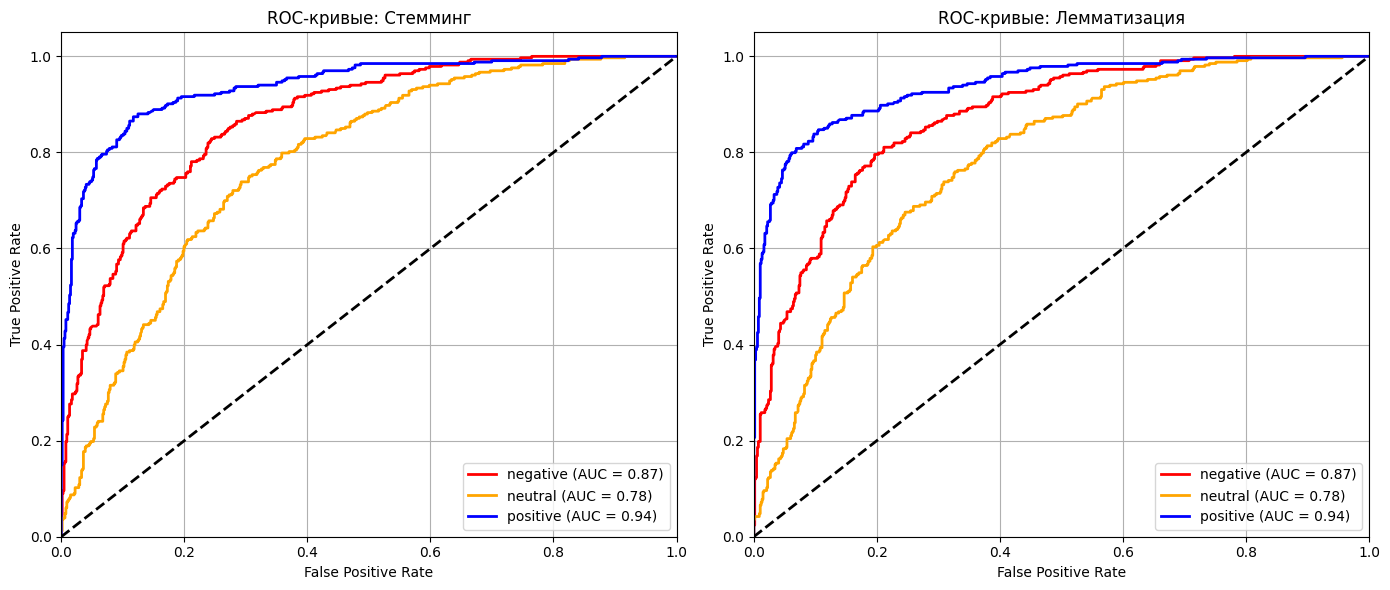

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Метки классов для графиков
class_names = ['negative', 'neutral', 'positive']
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# Получаем вероятности для ROC-кривых
y_score_stem = model_stem.predict_proba(X_test_stem_vec)
y_score_lemma = model_lemma.predict_proba(X_test_lemma_vec)

# Визуализация Матриц ошибок (Confusion Matrices)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Матрица для Стемминга
cm_stem = confusion_matrix(y_test, y_pred_stem)
sns.heatmap(
    cm_stem,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=class_names,
    yticklabels=class_names,
)
axes[0].set_title('Матрица ошибок: Стемминг')
axes[0].set_xlabel('Предсказанный класс')
axes[0].set_ylabel('Истинный класс')

# Матрица для Лемматизации
cm_lemma = confusion_matrix(y_test, y_pred_lemma)
sns.heatmap(
    cm_lemma,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1],
    xticklabels=class_names,
    yticklabels=class_names,
)
axes[1].set_title('Матрица ошибок: Лемматизация')
axes[1].set_xlabel('Предсказанный класс')
axes[1].set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()


# Визуализация Мультиклассовых ROC-кривых
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['red', 'orange', 'blue']

# ROC для Стемминга
for i, color in zip(range(3), colors):
  fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_stem[:, i])
  roc_auc = auc(fpr, tpr)
  axes[0].plot(
      fpr,
      tpr,
      color=color,
      lw=2,
      label=f'{class_names[i]} (AUC = {roc_auc:.2f})',
  )
axes[0].plot([0, 1], [0, 1], 'k--', lw=2)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC-кривые: Стемминг')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# ROC для Лемматизации
for i, color in zip(range(3), colors):
  fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_lemma[:, i])
  roc_auc = auc(fpr, tpr)
  axes[1].plot(
      fpr,
      tpr,
      color=color,
      lw=2,
      label=f'{class_names[i]} (AUC = {roc_auc:.2f})',
  )
axes[1].plot([0, 1], [0, 1], 'k--', lw=2)
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые: Лемматизация')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Как вы считаете, почему мы предсказываем позитивный и негативный сентимент лучше, чем нейтральный?

## Посмотрим на модель изнутри

In [ ]:
# Получаем фичи и веса
feature_names = vec_lemma.get_feature_names_out()
coefficients = model_lemma.coef_
class_names = ['negative', 'neutral', 'positive']

print(' Топ-10 слов-маркеров для каждого класса (Лемматизация) ')

for i, class_name in enumerate(class_names):
  # Сортируем веса по убыванию (самые сильные положительные коэффициенты для класса)
  top_indices = coefficients[i].argsort()[::-1][:10]

  # Собираем пары: слово + его вес
  words_with_weights = [
      f'{feature_names[idx]} ({coefficients[i][idx]:.2f})'
      for idx in top_indices
  ]

  print(f'\nКласс: {class_name.upper()}')
  print(', '.join(words_with_weights))

 Топ-10 слов-маркеров для каждого класса (Лемматизация) 

Класс: NEGATIVE
ужасный (0.96), ужас (0.60), ужасно (0.55), спор (0.52), плохой (0.52), советовать (0.50), вообще (0.47), пижама (0.42), товар (0.41), расстраивать (0.41)

Класс: NEUTRAL
нормальный (0.44), часть (0.38), огорчать (0.36), большой (0.34), долго (0.31), синтетика (0.31), расцветка (0.31), узкий (0.31), сожаление (0.31), оказываться (0.30)

Класс: POSITIVE
отличный (1.39), спасибо (1.15), супер (1.02), отлично (0.86), хороший (0.83), классный (0.79), довольный (0.71), приятный (0.68), идеально (0.58), рекомендовать (0.58)


### Попробуем создать интерактивную ячейку, которая будет классифицировать введенный отзыв и рассказывать, на основе чего был сделан вывод

In [ ]:
import pandas as pd

# Интерактивная ячейка для предсказания сентимента нового отзыва

inverse_sentiment_mapping = {0: 'negative', 1: 'neutral', 2: 'positive'}

user_review = input('Введите текст отзыва для классификации: ')

if user_review.strip():
  # Предобработка тем же методом лемматизации
  cleaned_review = preprocess_lemmatization(user_review)

  # Векторизация текста
  review_vector = vec_lemma.transform([cleaned_review])

  # Предсказание класса и расчет вероятностей
  pred_class_idx = model_lemma.predict(review_vector)[0]
  pred_probs = model_lemma.predict_proba(review_vector)[0]
  predicted_sentiment = inverse_sentiment_mapping[pred_class_idx]

  # Расчет вклада слов для предсказанного класса
  feature_names = vec_lemma.get_feature_names_out()
  # Извлекаем токены, попавшие в матрицу признаков для этого отзыва
  nonzero_indices = review_vector.nonzero()[1]

  word_contributions = []
  for idx in nonzero_indices:
    word = feature_names[idx]
    count = review_vector[0, idx]
    # Вклад = вес слова для предсказанного класса * сколько раз встречалось
    weight = model_lemma.coef_[pred_class_idx][idx]
    contribution = weight * count
    word_contributions.append((word, count, weight, contribution))

  # Сортируем слова по убыванию вклада
  word_contributions.sort(key=lambda x: x[3], reverse=True)

  # Вывод результата
  print(f' Исходный текст: "{user_review}"')
  print(f' После лемматизации: "{cleaned_review}"')
  print(f' Предсказанный класс: {predicted_sentiment.upper()}')
  print()
  print(' Распределение вероятностей по классам:')
  for idx, prob in enumerate(pred_probs):
    class_name = inverse_sentiment_mapping[idx]
    bar = '█' * int(prob * 20)
    print(f'   - {class_name:<8} : {prob * 100:5.2f}%  {bar}')

  print()
  print(
      f' Вклад слов в класс [{predicted_sentiment.upper()}] (Intercept:'
      f' {model_lemma.intercept_[pred_class_idx]:.2f}):'
  )

  if word_contributions:
    for word, count, weight, contrib in word_contributions:
      # Визуальный знак вклада (+ тянет К классу, - тянет ОТ класса)
      sign = '+' if contrib > 0 else ''
      print(
          f'   • {word:<15} | кол-во: {count} | вес: {weight:+.2f} | вклад:'
          f' {sign}{contrib:.2f}'
      )
  else:
    print(
        '   (Ни одно из слов отзыва не найдено в словаре модели или все слова'
        ' попали в стоп-слова)'
    )

    print('=' * 60)
else:
    print('Вы не ввели текст. Попробуйте еще раз!')

Введите текст отзыва для классификации: отличный фильм
 Исходный текст: "отличный фильм"
 После лемматизации: "отличный  фильм "
 Предсказанный класс: POSITIVE

 Распределение вероятностей по классам:
   - negative :  8.41%  █
   - neutral  : 12.49%  ██
   - positive : 79.10%  ███████████████

 Вклад слов в класс [POSITIVE] (Intercept: -0.03):
   • отличный        | кол-во: 1 | вес: +1.39 | вклад: +1.39


## Дополнительные материалы:

* Про мешок слов: https://www.freecodecamp.org/news/an-introduction-to-bag-of-words-and-how-to-code-it-in-python-for-nlp-282e87a9da04/
* Видео "Введение в NLP, Word2Vec": https://www.youtube.com/watch?v=MBQdMQUZMQM
* Курс по NLP, Transformers, LLMs: https://huggingface.co/learn/llm-course/chapter1/10
* Статья про BERT модели: https://jalammar.github.io/illustrated-bert/
* Курс по NLP от МФТИ: https://dls.samcs.ru/part2
* Про библиотеку SpaCy, которая понадобится для выполнения дополнительного задания: https://spacy.io/


## Задание: https://disk.360.yandex.ru/d/J2gFYa0Y9X4-GQ
### Данные: https://disk.360.yandex.ru/client/aa/d_CzqX9FytAo3uHg/

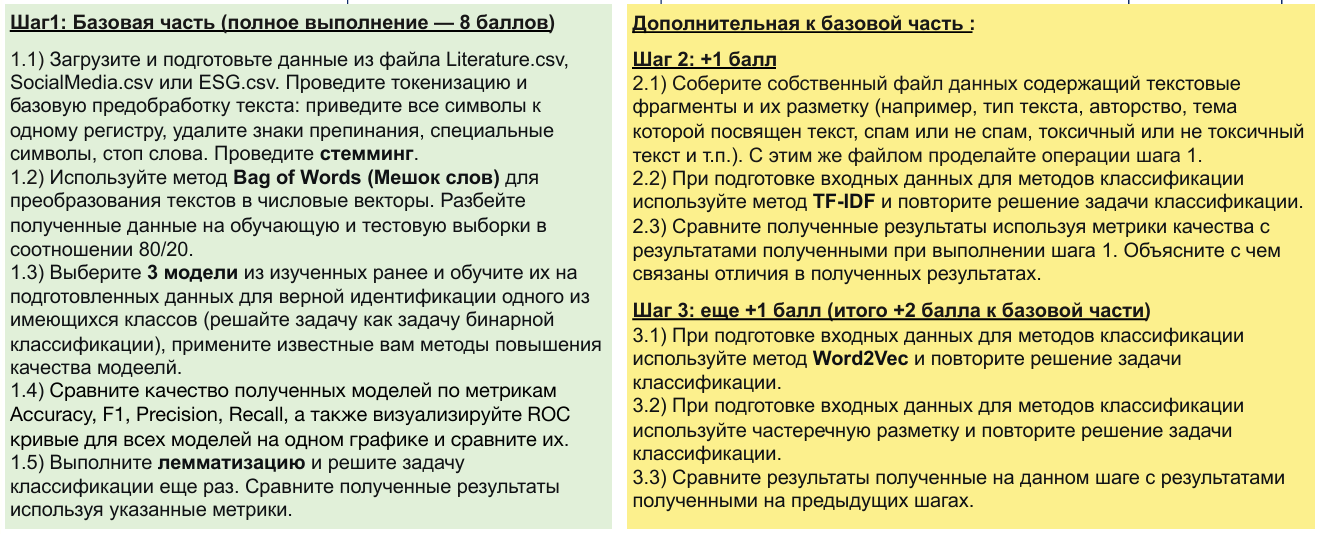